In [29]:
#import libraries
import glob
from keras.models import Sequential, load_model
import numpy as np
import pandas as pd
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import matplotlib.pyplot as plt
import keras as k
import datetime

In [30]:
df = pd.read_csv('./output_file.csv')

df.head()

,w1,w2,w3,wPL,range
0,0.19,0.63,0.94,0.000029,168.577083
1,0.43,0.69,0.95,0.000073,193.161944
2,0.62,0.12,0.12,0.000062,125.559007
3,0.53,0.65,0.41,0.000032,98.348028
4,0.41,0.44,0.18,0.000074,134.261982


In [31]:
df.shape

(702, 5)

In [32]:
#Drop the rows with na or missing values
df = df.dropna(axis=0)

df.shape

(702, 5)

In [33]:
#Split the data into independent (X) data set -features  and (Y) data set -targets
X = df.drop(['range'], axis=1)

Y = df['range']

In [34]:
X.head()

,w1,w2,w3,wPL
0,0.19,0.63,0.94,0.000029
1,0.43,0.69,0.95,0.000073
2,0.62,0.12,0.12,0.000062
3,0.53,0.65,0.41,0.000032
4,0.41,0.44,0.18,0.000074


In [35]:
Y.head()

0    168.577083
1    193.161944
2    125.559007
3     98.348028
4    134.261982
Name: range, dtype: float64

In [36]:
#Feature Scaling
#min-max scaler method scales the data set so that all the input features lie between 0 and 1
X_scaler = MinMaxScaler()
X_scaler.fit(X)
column_names = X.columns
X[column_names] = X_scaler.transform(X)

pd.DataFrame(X)


,w1,w2,w3,wPL
0,0.19,0.63,0.94,0.29
1,0.43,0.69,0.95,0.73
2,0.62,0.12,0.12,0.62
3,0.53,0.65,0.41,0.32
4,0.41,0.44,0.18,0.74
...,...,...,...,...
697,0.48,0.68,0.21,0.28
698,0.39,0.76,0.62,0.48
699,0.92,0.35,0.22,0.75
700,0.95,0.54,0.54,0.73


In [37]:
#Split the data into 80% training and 20% testing and Shuffle
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, shuffle=True)

In [38]:
#Build the model
model = Sequential()
model.add(Dense(256, input_dim=len(X.columns), kernel_initializer='random_normal', activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/Users/danish/miniforge3/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [39]:

# Compile the model
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy'])


In [40]:
from tensorflow.keras.callbacks import EarlyStopping

In [41]:

early_stopping = EarlyStopping('val_loss', patience=10, restore_best_weights=True)

In [42]:
# Train the model

history = model.fit(X_train, Y_train, epochs=100, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0000e+00 - loss: 23825.4082 - val_accuracy: 0.0000e+00 - val_loss: 25278.8906
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.0000e+00 - loss: 24101.5625 - val_accuracy: 0.0000e+00 - val_loss: 25237.1562
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.0000e+00 - loss: 24895.8262 - val_accuracy: 0.0000e+00 - val_loss: 25202.4629
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.0000e+00 - loss: 24577.3594 - val_accuracy: 0.0000e+00 - val_loss: 25181.6230
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.0000e+00 - loss: 24178.0352 - val_accuracy: 0.0000e+00 - val_loss: 25171.7852
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.0000e+00 - loss: 24212.2773 - val_accuracy: 0.0000e+00 - val_loss: 25167.3105
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.0000e+00 - loss: 23931.6465 - val_accuracy: 0.0000e+00 - val_loss: 25165.1152

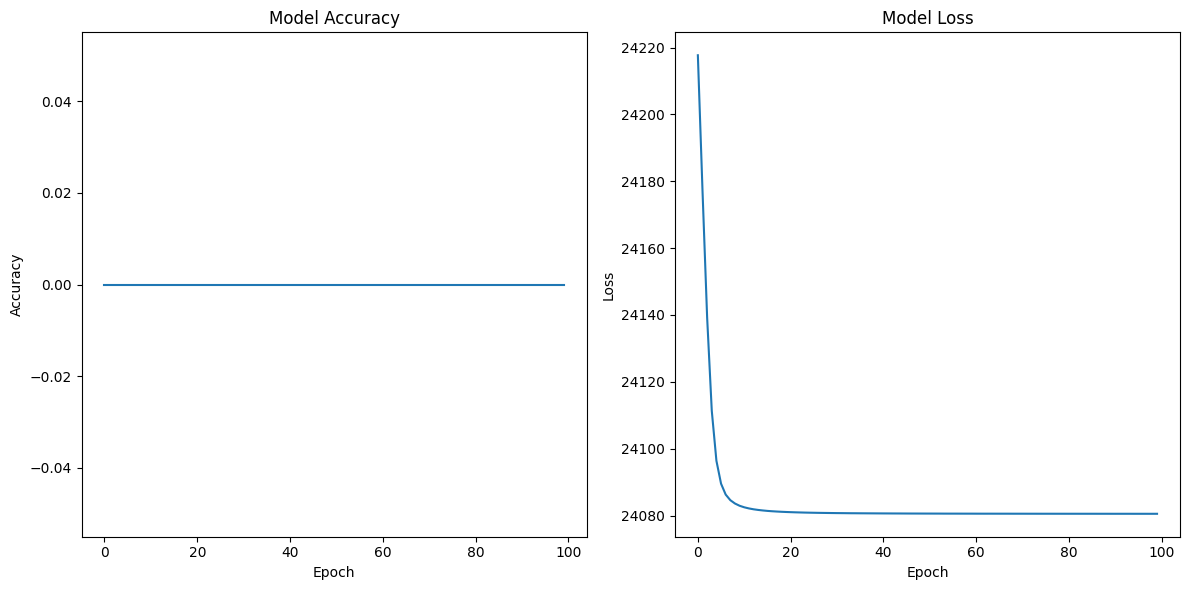

In [43]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()


In [44]:
print('shape of training data:', X_train.shape)
print('shape of test data:', X_test.shape)
X_train.head()

shape of training data: (561, 4)
shape of test data: (141, 4)


,w1,w2,w3,wPL
583,0.50,0.62,0.58,0.90
220,0.31,0.95,0.98,0.50
124,0.90,0.20,0.30,0.67
344,0.28,0.88,0.44,0.28
533,0.45,0.13,0.01,0.21


In [45]:
pred = model.predict(X_test)
pd.DataFrame(pred)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


,0
0,0.999996
1,0.999774
2,0.999159
3,0.999999
4,0.999990
...,...
136,0.999939
137,0.999999
138,0.999978
139,0.999951
